In [3]:
import os, sys
from pathlib import Path

ROOT = Path(r"C:\Users\gabyd\contract-clause-nlp") 
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(os.getcwd())

C:\Users\gabyd\contract-clause-nlp


In [4]:
import json, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import softmax
from scipy.stats import binomtest
from sklearn.metrics import f1_score, accuracy_score
from src.data import load_ledgar
from src.evaluate import ece

ds, names = load_ledgar()
y = np.array(ds["test"]["label"])
ytr = np.array(ds["train"]["label"])

bert_prob = softmax(np.load("results/legalbert_e10_s42/test_logits.npy"), axis=1)
bert_pred = bert_prob.argmax(1)
base_pred = np.load("results/baseline/test_pred.npy")
print("Legal-BERT acc", accuracy_score(y, bert_pred), "| baseline acc", accuracy_score(y, base_pred))

c:\Users\gabyd\contract-clause-nlp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Legal-BERT acc 0.8843 | baseline acc 0.8775


In [9]:
texts = np.array(ds["test"]["text"], dtype=object)
conf = bert_prob.max(1)
wrong = np.where(bert_pred != y)[0]
top = wrong[np.argsort(-conf[wrong])][:50]          # the 50 most confident mistakes
pd.DataFrame({
    "idx": top,
    "confidence": conf[top].round(3),
    "true_label": [names[i] for i in y[top]],
    "predicted_label": [names[i] for i in bert_pred[top]],
    "text": texts[top],
    "category": "",
    "comment": "",
}).to_csv("results/errors_top50.csv", index=False, encoding="utf-8-sig")   # utf-8-sig so Excel opens it cleanly

In [10]:
# McNemar (exact) on accuracy
base_ok, bert_ok = base_pred == y, bert_pred == y
b = int((base_ok & ~bert_ok).sum())   # only baseline right
c = int((~base_ok & bert_ok).sum())   # only Legal-BERT right
print(f"only baseline right: {b} | only Legal-BERT right: {c} | "
      f"McNemar exact p = {binomtest(b, b + c, 0.5).pvalue:.4f}")

# Paired bootstrap on the macro-F1 difference
rng = np.random.default_rng(0)
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    diffs.append(f1_score(y[i], bert_pred[i], average="macro") - f1_score(y[i], base_pred[i], average="macro"))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"macro-F1 difference (Legal-BERT - baseline): {np.mean(diffs):+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}]")

only baseline right: 325 | only Legal-BERT right: 393 | McNemar exact p = 0.0124
macro-F1 difference (Legal-BERT - baseline): +0.0031, 95% CI [-0.0073, +0.0127]


In [11]:
buckets = json.load(open("results/class_buckets.json"))
name2id = {n: i for i, n in enumerate(names)}
rows = []
for bucket, labels in buckets.items():
    ids = [name2id[n] for n in labels]
    for model, pred in [("TF-IDF", base_pred), ("Legal-BERT", bert_pred)]:
        rows.append({"bucket": bucket, "model": model,
                     "macro_f1": f1_score(y, pred, labels=ids, average="macro", zero_division=0)})
by_bucket = pd.DataFrame(rows).pivot(index="bucket", columns="model", values="macro_f1").loc[["head", "torso", "tail"]]
by_bucket.to_csv("results/f1_by_bucket.csv"); by_bucket.round(3)

model,Legal-BERT,TF-IDF
bucket,,
head,0.912,0.900
torso,0.864,0.858
tail,0.755,0.759


Legal-BERT worse:
              class  train_n  f1_tfidf  f1_bert   gain
14           Books       23     1.000    0.800 -0.200
36  Enforceability      244     0.690    0.581 -0.109
50       Indemnity      271     0.735    0.630 -0.105
70          Powers      125     0.640    0.552 -0.088
37    Enforcements      201     0.685    0.600 -0.085 

Legal-BERT better:
              class  train_n  f1_tfidf  f1_bert   gain
72  Qualifications       47     0.571    0.667  0.095
35      Employment      308     0.713    0.809  0.096
69       Positions      190     0.603    0.714  0.111
95         Vesting      451     0.821    0.933  0.112
56   Jurisdictions      202     0.385    0.590  0.206


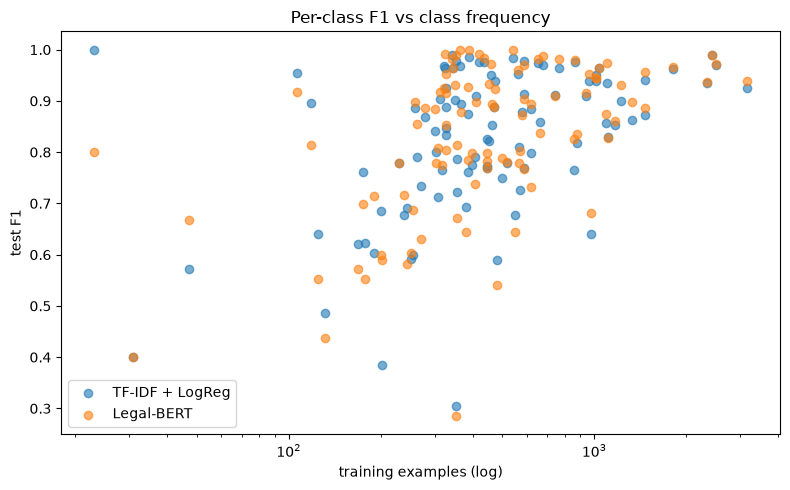

In [12]:
freq = np.bincount(ytr, minlength=len(names))
f1_base = f1_score(y, base_pred, labels=range(len(names)), average=None, zero_division=0)
f1_bert = f1_score(y, bert_pred, labels=range(len(names)), average=None, zero_division=0)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(freq, f1_base, alpha=.6, label="TF-IDF + LogReg")
ax.scatter(freq, f1_bert, alpha=.6, label="Legal-BERT")
ax.set_xscale("log"); ax.set_xlabel("training examples (log)"); ax.set_ylabel("test F1")
ax.set_title("Per-class F1 vs class frequency"); ax.legend()
plt.tight_layout(); plt.savefig("results/figures/f1_vs_frequency.png", dpi=150)

delta = pd.DataFrame({"class": names, "train_n": freq, "f1_tfidf": f1_base,
                      "f1_bert": f1_bert, "gain": f1_bert - f1_base}).sort_values("gain")
print("Legal-BERT worse:\n", delta.head(5).round(3), "\n\nLegal-BERT better:\n", delta.tail(5).round(3))

In [13]:
conf = pd.read_csv("results/legalbert_e10_s42/top_confusions.csv")
predicted = {("Assigns", "Assignments"), ("Costs", "Expenses"), ("Venues", "Governing Laws"),
             ("Consent To Jurisdiction", "Governing Laws"), ("Waivers", "No Waivers"),
             ("Applicable Laws", "Governing Laws")}
conf["predicted_in_EDA"] = [(t, p) in predicted or (p, t) in predicted for t, p in zip(conf.true, conf.predicted)]
conf.head(15)

,true,predicted,count,predicted_in_EDA
0,Applicable Laws,Governing Laws,33,True
1,Definitions,Defined Terms,24,False
2,Tax Withholdings,Withholdings,24,False
3,Authorizations,Authority,16,False
4,Successors,Binding Effects,16,False
5,Modifications,Amendments,15,False
6,No Waivers,Waivers,14,True
7,Integration,Entire Agreements,13,False
8,General,Payments,12,False
9,Withholdings,Tax Withholdings,12,False


In [5]:
vec, clf = joblib.load("models/baseline.joblib")
base_prob = clf.predict_proba(vec.transform(ds["test"]["text"]))
print(f"ECE baseline: {ece(base_prob, y):.3f} | ECE Legal-BERT: {ece(bert_prob, y):.3f}")

ECE baseline: 0.020 | ECE Legal-BERT: 0.084


In [15]:
groups = [
    {"Governing Laws", "Applicable Laws"},
    {"Definitions", "Defined Terms"},
    {"Tax Withholdings", "Withholdings"},
    {"Authority", "Authorizations"},
    {"Waivers", "No Waivers"},
    {"Amendments", "Modifications"},
    {"Entire Agreements", "Integration"},
    {"Indemnity", "Indemnifications"},
    {"Successors", "Binding Effects"},
]
for g in groups:
    assert g <= set(names), g - set(names)   # catches spelling mistakes

canon = np.arange(len(names))                # map each label to one representative of its group
for g in groups:
    ids = sorted(name2id[n] for n in g)
    canon[ids] = ids[0]

for model, pred in [("TF-IDF", base_pred), ("Legal-BERT", bert_pred)]:
    err = pred != y
    within = err & (canon[pred] == canon[y])
    print(f"{model}: {within.sum()} of {err.sum()} errors ({within.mean() / err.mean():.1%}) are between near-synonym labels | "
          f"accuracy {accuracy_score(y, pred):.4f} → {accuracy_score(canon[y], canon[pred]):.4f} if those labels are merged | "
          f"macro-F1 {f1_score(y, pred, average='macro'):.4f} → {f1_score(canon[y], canon[pred], average='macro'):.4f}")

TF-IDF: 230 of 1225 errors (18.8%) are between near-synonym labels | accuracy 0.8775 → 0.9005 if those labels are merged | macro-F1 0.8267 → 0.8494
Legal-BERT: 241 of 1157 errors (20.8%) are between near-synonym labels | accuracy 0.8843 → 0.9084 if those labels are merged | macro-F1 0.8298 → 0.8555


In [19]:
sets = {"Colab/Kaggle": "results/legalbert_e10_s{}", "local GPU": "results/local_gpu/legalbert_e10_s{}"}
rows = []
for set_name, pattern in sets.items():
    for s in [42, 1, 2]:
        m = json.load(open(pattern.format(s) + "/test_metrics.json"))
        rows.append({"set": set_name, "seed": s,
                     **{k: m[k] for k in ["accuracy", "macro_f1", "macro_f1_dedup", "ece"]}})
runs = pd.DataFrame(rows)
display(runs.round(4))

per_set = runs.groupby("set")[["accuracy", "macro_f1", "ece"]].agg(["mean", "std"]).round(4)
overall = runs[["accuracy", "macro_f1", "macro_f1_dedup", "ece"]].agg(["mean", "std"]).round(4)
same_seed_gap = runs.pivot(index="seed", columns="set", values="macro_f1").diff(axis=1).iloc[:, -1].abs()
print("same seed, different hardware: macro-F1 gap", same_seed_gap.round(4).to_dict())
json.dump({"runs": rows, "overall": overall.to_dict()}, open("results/legalbert_runs_summary.json", "w"), indent=2)
display(per_set); display(overall)

,set,seed,accuracy,macro_f1,macro_f1_dedup,ece
0,Colab/Kaggle,42,0.8843,0.8298,0.8262,0.0844
1,Colab/Kaggle,1,0.8873,0.8318,0.8284,0.0827
2,Colab/Kaggle,2,0.8827,0.8240,0.8204,0.0846
3,local GPU,42,0.8862,0.8273,0.8238,0.0813
4,local GPU,1,0.8841,0.8256,0.8222,0.0828
5,local GPU,2,0.8823,0.8233,0.8198,0.0846


same seed, different hardware: macro-F1 gap {1: 0.0062, 2: 0.0007, 42: 0.0025}


accuracy         macro_f1            ece        
                 mean     std     mean    std    mean     std
set                                                          
Colab/Kaggle   0.8848  0.0023   0.8286  0.004  0.0839  0.0011
local GPU      0.8842  0.0020   0.8254  0.002  0.0829  0.0017

,accuracy,macro_f1,macro_f1_dedup,ece
mean,0.8845,0.8270,0.8235,0.0834
std,0.0019,0.0033,0.0033,0.0014


In [6]:
from scipy.optimize import minimize_scalar

yv = np.array(ds["validation"]["label"])

def nll(T, logits, labels):
    p = softmax(logits / T, axis=1)
    return -np.log(p[np.arange(len(labels)), labels] + 1e-12).mean()

cal = {}
for s in [1, 2]:                                    # Kaggle seeds that have val_logits.npy
    vl = np.load(f"results/legalbert_e10_s{s}/val_logits.npy")
    tl = np.load(f"results/legalbert_e10_s{s}/test_logits.npy")
    T = minimize_scalar(lambda t: nll(t, vl, yv), bounds=(0.5, 10), method="bounded").x
    cal[s] = {"T": T, "val_prob": softmax(vl / T, axis=1), "test_prob": softmax(tl / T, axis=1),
              "test_raw": softmax(tl, axis=1)}
    print(f"seed {s}: T = {T:.2f} (fitted on validation) | test ECE {ece(cal[s]['test_raw'], y):.3f} "
          f"-> {ece(cal[s]['test_prob'], y):.3f} | test NLL {nll(1, tl, y):.3f} -> {nll(T, tl, y):.3f}")

base_val_prob = clf.predict_proba(vec.transform(ds["validation"]["text"]))
print(f"TF-IDF (no scaling needed): test ECE {ece(base_prob, y):.3f}")

seed 1: T = 1.45 (fitted on validation) | test ECE 0.083 -> 0.024 | test NLL 0.623 -> 0.515
seed 2: T = 1.43 (fitted on validation) | test ECE 0.085 -> 0.028 | test NLL 0.639 -> 0.530
TF-IDF (no scaling needed): test ECE 0.020


,target,model,threshold (val),test coverage,test accuracy
0,0.95,Legal-BERT s1 (calibrated),0.890,0.812,0.951
1,0.95,Legal-BERT s2 (calibrated),0.890,0.812,0.948
2,0.95,TF-IDF + LogReg,0.740,0.830,0.946
3,0.97,Legal-BERT s1 (calibrated),0.950,0.580,0.972
4,0.97,Legal-BERT s2 (calibrated),0.940,0.653,0.968
5,0.97,TF-IDF + LogReg,0.880,0.726,0.965
6,0.99,Legal-BERT s1 (calibrated),0.974,0.265,0.985
7,0.99,Legal-BERT s2 (calibrated),0.972,0.314,0.986
8,0.99,TF-IDF + LogReg,0.986,0.438,0.983


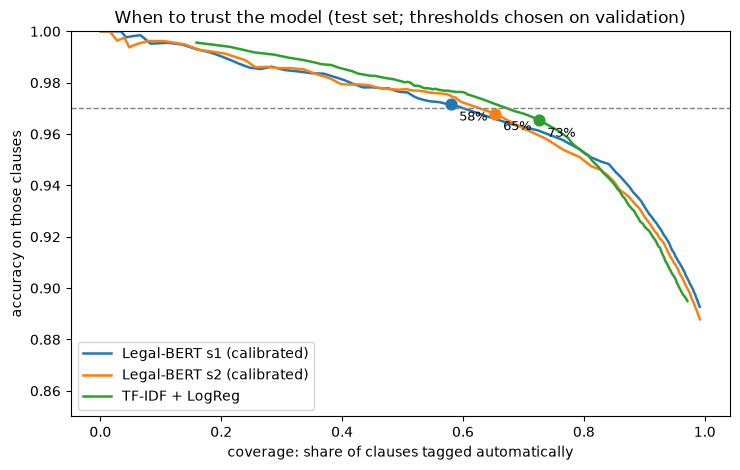

In [7]:
THRESHOLDS = np.unique(np.round(np.concatenate([np.arange(0.30, 0.95, 0.01),
                                                np.arange(0.95, 0.9995, 0.001)]), 4))

def at(prob, labels, t):
    m = prob.max(1) >= t
    acc = (prob.argmax(1)[m] == labels[m]).mean() if m.any() else np.nan
    return m.mean(), acc

def curve(prob, labels):
    return pd.DataFrame([dict(zip(["threshold", "coverage", "accuracy"], (t, *at(prob, labels, t))))
                         for t in THRESHOLDS])

def pick(val_prob, labels, target):
    """Lowest threshold whose VALIDATION accuracy reaches the target (None if never reached)."""
    c = curve(val_prob, labels).dropna()
    ok = c[c.accuracy >= target]
    return None if ok.empty else float(ok.threshold.min())

models = {f"Legal-BERT s{s} (calibrated)": (cal[s]["val_prob"], cal[s]["test_prob"]) for s in cal}
models["TF-IDF + LogReg"] = (base_val_prob, base_prob)

rows = []
for target in [0.95, 0.97, 0.99]:
    for name, (pv, pt) in models.items():
        t = pick(pv, yv, target)
        cov, acc = at(pt, y, t) if t is not None else (np.nan, np.nan)
        rows.append({"target": target, "model": name, "threshold (val)": t,
                     "test coverage": cov, "test accuracy": acc})
abst = pd.DataFrame(rows)
display(abst.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for name, (pv, pt) in models.items():
    c = curve(pt, y).dropna()
    ax.plot(c.coverage, c.accuracy, label=name, lw=1.8)
    t = pick(pv, yv, 0.97)
    if t is not None:
        cov, acc = at(pt, y, t)
        ax.scatter([cov], [acc], s=60, zorder=3)
        ax.annotate(f"{cov:.0%}", (cov, acc), textcoords="offset points", xytext=(6, -12), fontsize=9)
ax.axhline(0.97, ls="--", lw=1, color="grey")
ax.set_xlabel("coverage: share of clauses tagged automatically")
ax.set_ylabel("accuracy on those clauses")
ax.set_title("When to trust the model (test set; thresholds chosen on validation)")
ax.set_ylim(0.85, 1.0); ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig("results/figures/abstention_curve.png", dpi=150)

out = {"temperature": {f"seed_{s}": round(float(cal[s]["T"]), 4) for s in cal},
       "ece_test": {**{f"seed_{s}_raw": round(ece(cal[s]["test_raw"], y), 4) for s in cal},
                    **{f"seed_{s}_calibrated": round(ece(cal[s]["test_prob"], y), 4) for s in cal},
                    "tfidf": round(ece(base_prob, y), 4)},
       "abstention": abst.replace({np.nan: None}).to_dict(orient="records")}
json.dump(out, open("results/abstention.json", "w"), indent=2)
abst.to_csv("results/abstention_table.csv", index=False)

In [14]:
def top_acc(prob, labels, frac):
    order = np.argsort(-prob.max(1))[: int(round(frac * len(labels)))]
    return (prob.argmax(1)[order] == labels[order]).mean()

def summarise(name, val_prob, test_prob):
    t = pick(val_prob, yv, 0.97)
    cov, acc = at(test_prob, y, t) if t is not None else (np.nan, np.nan)
    pred = test_prob.argmax(1)
    return {"model": name,
            "accuracy": accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, average="macro"),
            "ece": ece(test_prob, y),
            "val_accuracy": accuracy_score(yv, val_prob.argmax(1)),
            "val_macro_f1": f1_score(yv, val_prob.argmax(1), average="macro"),
            "threshold_97_val": t, "coverage_97": cov, "test_acc_at_threshold": acc,
            **{f"acc_top_{int(f * 100)}pct": top_acc(test_prob, y, f) for f in [0.5, 0.7, 0.8, 0.9]}}

rows = [summarise("TF-IDF + LogReg", base_val_prob, base_prob)]
for s in cal:
    rows.append(summarise(f"Legal-BERT s{s} (calibrated)", cal[s]["val_prob"], cal[s]["test_prob"]))
    rows.append(summarise(f"Ensemble s{s} (50/50 avg)", (cal[s]["val_prob"] + base_val_prob) / 2,
                          (cal[s]["test_prob"] + base_prob) / 2))
ensemble_summary = pd.DataFrame(rows).set_index("model")
display(ensemble_summary.round(4))

# significance of the ensemble over Legal-BERT alone (paired bootstrap + McNemar)
rng = np.random.default_rng(0)
sig = {}
for s in cal:
    p_bert = cal[s]["test_prob"].argmax(1)
    p_ens = ((cal[s]["test_prob"] + base_prob) / 2).argmax(1)
    d = []
    for _ in range(1000):
        i = rng.integers(0, len(y), len(y))
        d.append(f1_score(y[i], p_ens[i], average="macro") - f1_score(y[i], p_bert[i], average="macro"))
    ok, ob = p_ens == y, p_bert == y
    b, c = int((ob & ~ok).sum()), int((~ob & ok).sum())
    sig[f"seed_{s}"] = {"macro_f1_diff": float(np.mean(d)),
                        "ci95": [float(x) for x in np.percentile(d, [2.5, 97.5])],
                        "mcnemar_p": float(binomtest(b, b + c, 0.5).pvalue)}
print(json.dumps(sig, indent=2))

ensemble_summary.to_csv("results/ensemble_summary.csv")
json.dump({"summary": ensemble_summary.reset_index().replace({np.nan: None}).to_dict(orient="records"),
           "ensemble_vs_legalbert": sig}, open("results/ensemble.json", "w"), indent=2)

,accuracy,macro_f1,ece,val_accuracy,val_macro_f1,threshold_97_val,coverage_97,test_acc_at_threshold,acc_top_50pct,acc_top_70pct,acc_top_80pct,acc_top_90pct
model,,,,,,,,,,,,
TF-IDF + LogReg,0.8775,0.8267,0.0198,0.8793,0.8185,0.88,0.7258,0.9654,0.9804,0.9680,0.9528,0.9243
Legal-BERT s1 (calibrated),0.8873,0.8318,0.0238,0.8866,0.8248,0.95,0.5799,0.9717,0.9764,0.9626,0.9529,0.9318
Ensemble s1 (50/50 avg),0.8950,0.8438,0.0167,0.8945,0.8325,0.85,0.7655,0.9671,0.9858,0.9756,0.9611,0.9397
Legal-BERT s2 (calibrated),0.8827,0.8240,0.0280,0.8863,0.8230,0.94,0.6527,0.9680,0.9774,0.9620,0.9492,0.9279
Ensemble s2 (50/50 avg),0.8911,0.8360,0.0128,0.8933,0.8365,0.85,0.7653,0.9673,0.9856,0.9747,0.9620,0.9379


{
  "seed_1": {
    "macro_f1_diff": 0.01238358897468578,
    "ci95": [
      0.006120447855787703,
      0.020238177025482775
    ],
    "mcnemar_p": 7.880546230827447e-08
  },
  "seed_2": {
    "macro_f1_diff": 0.012123319748018191,
    "ci95": [
      0.007058137023660369,
      0.01727075933571871
    ],
    "mcnemar_p": 2.7207210583717808e-08
  }
}


In [13]:
# Does it also win on validation ?
for s in [1, 2]:
    pv_ens = (cal[s]["val_prob"] + base_val_prob) / 2
    for name, p in [("TF-IDF", base_val_prob), ("Legal-BERT", cal[s]["val_prob"]), ("Ensemble", pv_ens)]:
        print(f"seed {s} | {name:10s} | val acc {accuracy_score(yv, p.argmax(1)):.4f} | "
              f"val macro-F1 {f1_score(yv, p.argmax(1), average='macro'):.4f}")

seed 1 | TF-IDF     | val acc 0.8793 | val macro-F1 0.8185
seed 1 | Legal-BERT | val acc 0.8866 | val macro-F1 0.8248
seed 1 | Ensemble   | val acc 0.8945 | val macro-F1 0.8325
seed 2 | TF-IDF     | val acc 0.8793 | val macro-F1 0.8185
seed 2 | Legal-BERT | val acc 0.8863 | val macro-F1 0.8230
seed 2 | Ensemble   | val acc 0.8933 | val macro-F1 0.8365


In [12]:
# Is the ensemble’s gain over Legal-BERT significant?
rng = np.random.default_rng(0)
for s in [1, 2]:
    p_bert = cal[s]["test_prob"].argmax(1)
    p_ens = ((cal[s]["test_prob"] + base_prob) / 2).argmax(1)
    d = []
    for _ in range(1000):
        i = rng.integers(0, len(y), len(y))
        d.append(f1_score(y[i], p_ens[i], average="macro") - f1_score(y[i], p_bert[i], average="macro"))
    lo, hi = np.percentile(d, [2.5, 97.5])
    ok, ob = p_ens == y, p_bert == y
    b, c = int((ob & ~ok).sum()), int((~ob & ok).sum())
    print(f"seed {s}: ensemble - Legal-BERT macro-F1 {np.mean(d):+.4f} [{lo:+.4f}, {hi:+.4f}] | "
          f"McNemar p = {binomtest(b, b + c, 0.5).pvalue:.4g}")

seed 1: ensemble - Legal-BERT macro-F1 +0.0124 [+0.0061, +0.0202] | McNemar p = 7.881e-08
seed 2: ensemble - Legal-BERT macro-F1 +0.0121 [+0.0071, +0.0173] | McNemar p = 2.721e-08
